#Step 1: Import libraries and set plot styles

As the first step, we import various Python libraries which are useful for our data analysis, data visualization, calculation and model building tasks. When importing those libraries, we use the following conventions.

In [ ]:
# Import libraries and set plot styles
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('ggplot')
sns.set_palette("husl")

# Install required packages
!pip install GEOparse scikit-learn

#Step 2: Get and prepare data

The dataset that we use here is available in Scikit-learn. But it is not in the correct format that we want. So, we have to do some manipulations to get the dataset ready for our task. First, we load the dataset using Scikit-learn load_breast_cancer() function. Then, we convert the data into a pandas DataFrame which is the format we are familiar with.

07-Dec-2025 07:13:43 DEBUG utils - Directory ./ already exists. Skipping.
DEBUG:GEOparse:Directory ./ already exists. Skipping.
07-Dec-2025 07:13:43 INFO GEOparse - File already exist: using local version.
INFO:GEOparse:File already exist: using local version.
07-Dec-2025 07:13:43 INFO GEOparse - Parsing ./GSE6613_family.soft.gz: 
INFO:GEOparse:Parsing ./GSE6613_family.soft.gz: 
07-Dec-2025 07:13:43 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
07-Dec-2025 07:13:43 DEBUG GEOparse - SERIES: GSE6613
DEBUG:GEOparse:SERIES: GSE6613
07-Dec-2025 07:13:43 DEBUG GEOparse - PLATFORM: GPL96
DEBUG:GEOparse:PLATFORM: GPL96


07-Dec-2025 07:13:44 DEBUG GEOparse - SAMPLE: GSM153404
DEBUG:GEOparse:SAMPLE: GSM153404
07-Dec-2025 07:13:44 DEBUG GEOparse - SAMPLE: GSM153405
DEBUG:GEOparse:SAMPLE: GSM153405
07-Dec-2025 07:13:44 DEBUG GEOparse - SAMPLE: GSM153406
DEBUG:GEOparse:SAMPLE: GSM153406
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153407
DEBUG:GEOparse:SAMPLE: GSM153407
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153408
DEBUG:GEOparse:SAMPLE: GSM153408
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153409
DEBUG:GEOparse:SAMPLE: GSM153409
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153410
DEBUG:GEOparse:SAMPLE: GSM153410
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153411
DEBUG:GEOparse:SAMPLE: GSM153411
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153412
DEBUG:GEOparse:SAMPLE: GSM153412
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153413
DEBUG:GEOparse:SAMPLE: GSM153413
07-Dec-2025 07:13:45 DEBUG GEOparse - SAMPLE: GSM153414
DEBUG:GEOparse:SAMPLE: GSM153414
07-Dec-2025 07:13:45 

Processing gene expression data...
Raw data shape: (22283, 105)
Platform columns: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']
Cleaning and preprocessing data...
After cleaning: 105 genes, 22283 samples

First 5 genes and 5 samples:
name       GSM153404  GSM153405  GSM153406  GSM153407  GSM153408
ID_REF                                                          
1007_s_at      114.5      105.1      145.7      168.7       94.3
1053_at         64.4       58.4       52.5       45.4       51.3
117_at         206.3      179.8      192.0      263.6      211.9
121_at         507.0      497.8      346.3      430.7      485.5
1255_g_at       34.5       18.0       40.1       40.5       22.8


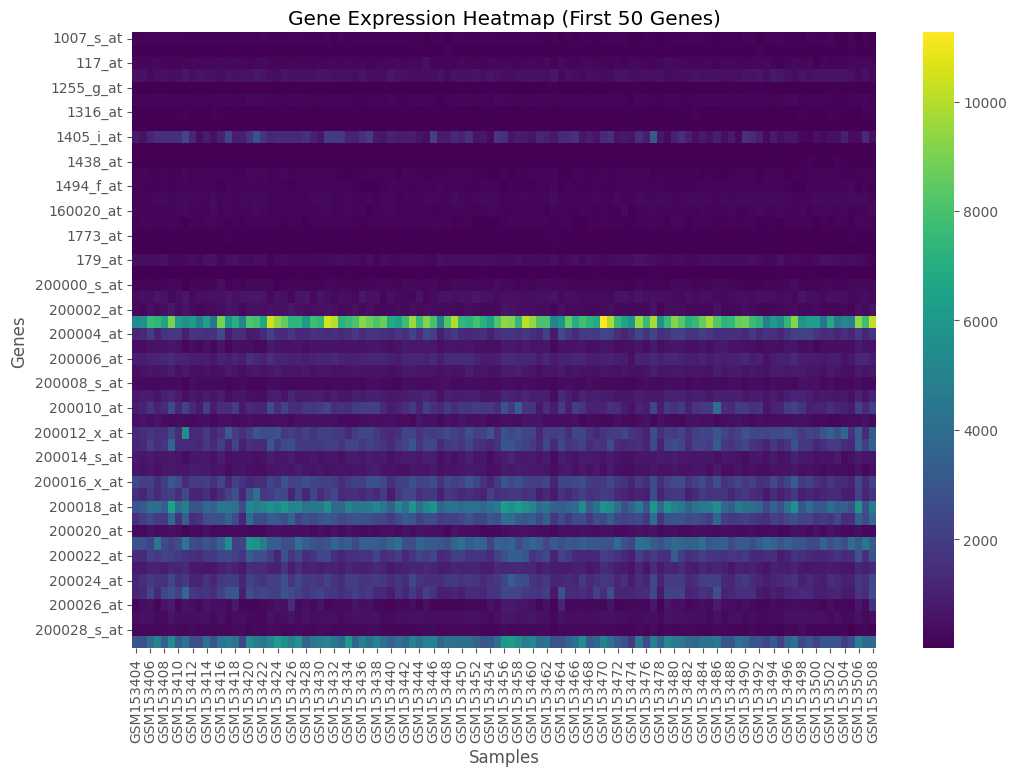

In [ ]:
# Import required libraries for gene data
import GEOparse
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load gene expression data from GEO
print("Downloading GSE6613 dataset...")
gse = GEOparse.get_GEO(geo="GSE6613", destdir="./")

# Get the expression data
print("Processing gene expression data...")
samples = gse.pivot_samples('VALUE')
print(f"Raw data shape: {samples.shape}")

gpl = gse.gpls[list(gse.gpls.keys())[0]]  # First platform
print("Platform columns:", gpl.table.columns.tolist())

# Create probe to gene mapping
probe_to_gene = dict(zip(gpl.table["ID"], gpl.table["Gene Symbol"]))
gene_titles = dict(zip(gpl.table["ID"], gpl.table["Gene Title"]))

# Clean the data
print("Cleaning and preprocessing data...")

# Remove rows with missing values
samples_clean = samples.dropna()

# Convert to numeric (handle any string values)
samples_numeric = samples_clean.apply(pd.to_numeric, errors='coerce')
samples_numeric = samples_numeric.dropna()

# Remove genes with zero variance
gene_variance = samples_numeric.var(axis=1)
samples_filtered = samples_numeric[gene_variance > 0]

print(f"After cleaning: {samples_filtered.shape[1]} genes, {samples_filtered.shape[0]} samples")

# Display first few rows
print("\nFirst 5 genes and 5 samples:")
print(samples_filtered.iloc[:5, :5])

# Create heatmap of a subset of data (first 50 genes and all samples)
plt.figure(figsize=(12, 8))
sns.heatmap(samples_filtered.iloc[:50, :], cmap='viridis', cbar=True)
plt.title('Gene Expression Heatmap (First 50 Genes)')
plt.xlabel('Samples')
plt.ylabel('Genes')
plt.show()


In [ ]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
print(df.shape)

(569, 30)


<Axes: >

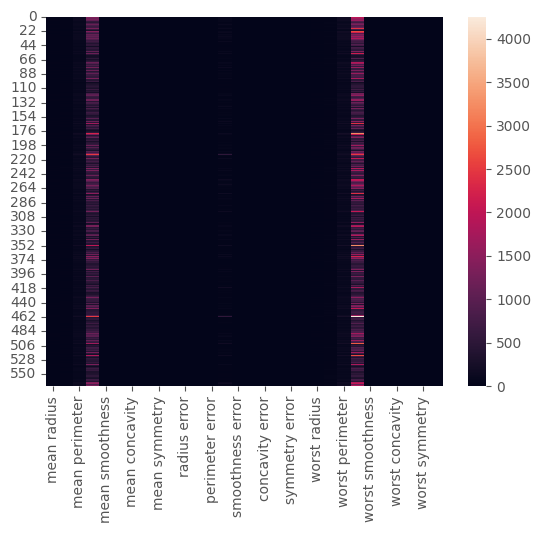

In [ ]:
sb.heatmap(df)

#Step 3: Apply PCA

In our breast_cancer dataset, the original feature space has 30 dimensions, known as d dimensions. PCA will project the data onto a smaller subspace of k dimensions (where k < d) while retaining as much of the variation as possible. These k dimensions are known as the principal components.

By applying PCA, we lose some of the variance (i.e., information). By reducing the dimensionality of the data, PCA will reduce the size of the data.

* This will improve the performance of machine learning algorithms.
* This will reduce hardware requirements and speed up the training process.
* This will allow us to easily understand the underlying structure of the data.
* This will allow us to visualize the data on a 2d or 3d plot (if we choose the number of principal components as 2 or 3).

#3.a: Obtain the feature matrix

The feature matrix contains the values of all 30 features in the dataset. It is a 569x30 two-dimensional Numpy array. It is stored in the X variable.

In [ ]:
# Prepare feature matrix (genes as features, samples as observations)
X = samples_filtered.values.T  # Transpose: samples as rows, genes as columns
print(f"Feature matrix shape: {X.shape}")

# ✅ FIXED PRINT
print(f"Samples: {X.shape[0]}, Genes: {X.shape[1]}")

# Store gene names for later use
gene_names = samples_filtered.index.tolist()
sample_names = samples_filtered.columns.tolist()


Feature matrix shape: (105, 22283)
Samples: 105, Genes: 22283


#3.b: Standardize the features if necessary

You can see that the values of the dataset are not equally scaled. So, we need to apply z-score standardization to get all features into the same scale. For this, we use Scikit-learn StandardScaler() class which is in the preprocessing submodule in Scikit-learn.

Data standardized successfully!
Original data - Mean: 180.088, Std: 1054.735
Scaled data - Mean: 0.000, Std: 1.000


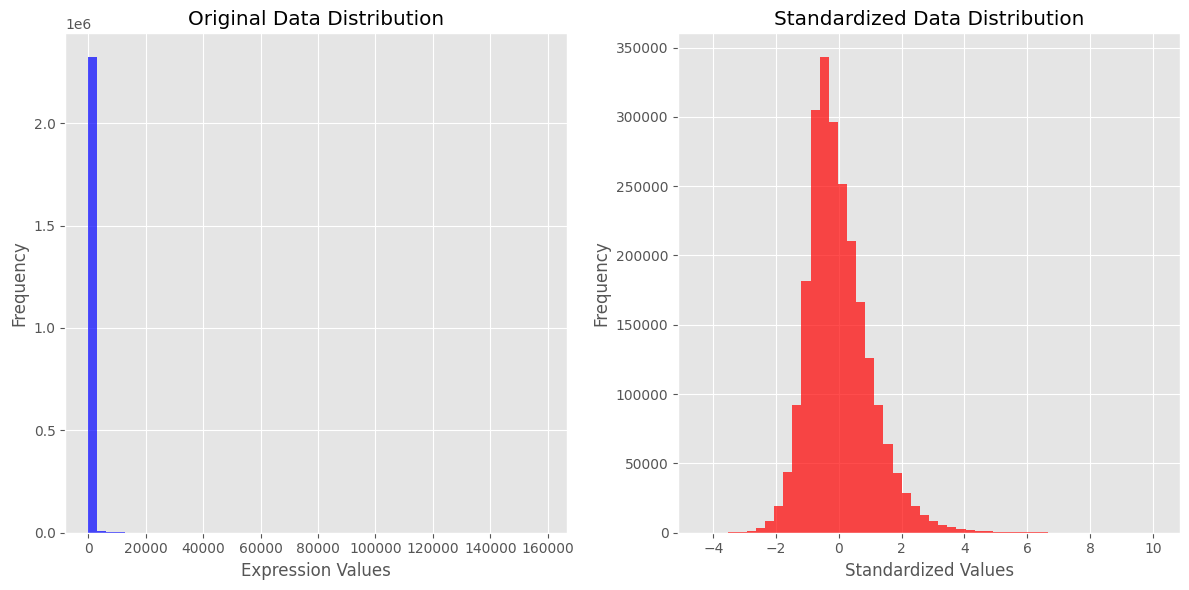

In [ ]:
# Standardize the features (important for PCA)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data standardized successfully!")
print(f"Original data - Mean: {X.mean():.3f}, Std: {X.std():.3f}")
print(f"Scaled data - Mean: {X_scaled.mean():.3f}, Std: {X_scaled.std():.3f}")

# Visualize standardized data (subset)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(X.flatten(), bins=50, alpha=0.7, color='blue')
plt.title('Original Data Distribution')
plt.xlabel('Expression Values')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(X_scaled.flatten(), bins=50, alpha=0.7, color='red')
plt.title('Standardized Data Distribution')
plt.xlabel('Standardized Values')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

<Axes: >

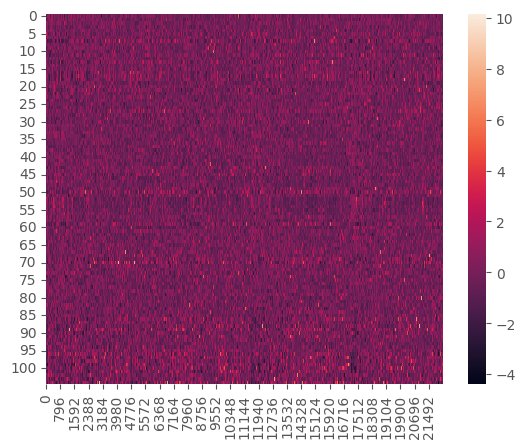

In [ ]:
sb.heatmap(X_scaled)

#3.c: Choose the right number of dimensions (k)

Now, we are ready to apply PCA for our dataset. Before that, we need to choose the right number of dimensions (i.e., the right number principal components — k). For this, we apply PCA with the original number of dimensions (i.e., 30) and see how well PCA captures the variance of the data.

Total components available: 105
First 10 components explain: 234.98% of variance
Components needed for 95% variance: 91


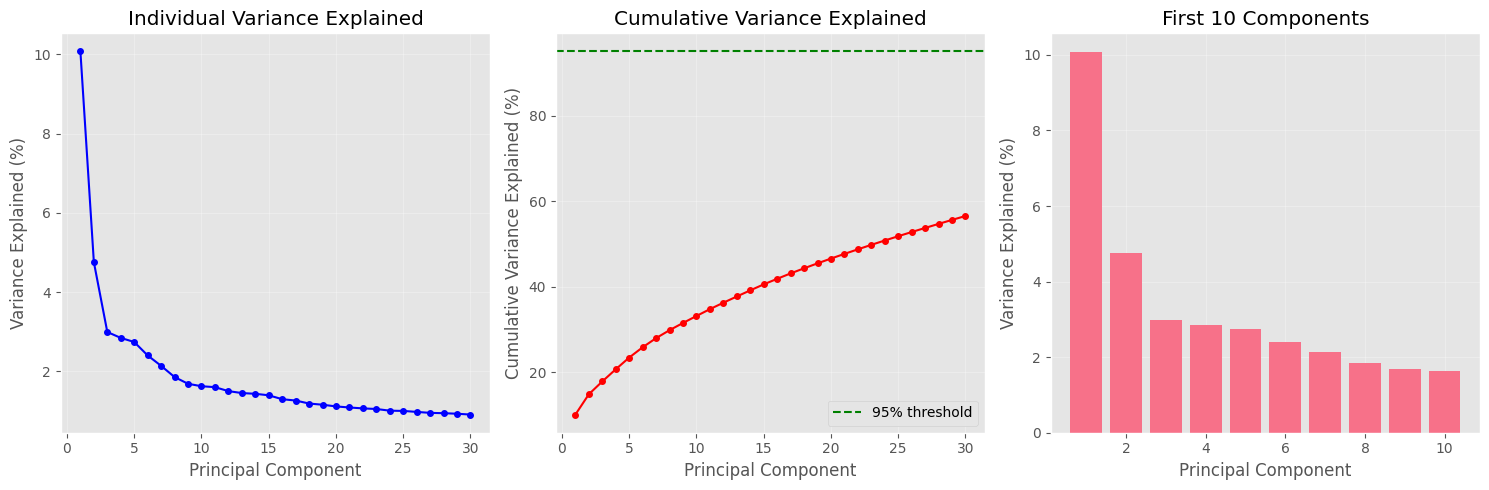

In [ ]:
# Apply PCA with all components to see variance explained
pca_full = PCA(random_state=2020)
pca_full.fit(X_scaled)

# Calculate cumulative variance explained
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_ * 100)
individual_variance = pca_full.explained_variance_ratio_ * 100

print(f"Total components available: {len(individual_variance)}")

# ✅ FIXED PRINT (First 10 cumulative variance)
print(f"First 10 components explain: {cumulative_variance[:10].sum():.2f}% of variance")

# Find number of components for 95% variance
n_components_95 = np.argmax(cumulative_variance >= 95) + 1
print(f"Components needed for 95% variance: {n_components_95}")

# Plot variance explained
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(range(1, min(31, len(individual_variance) + 1)),
         individual_variance[:30], 'bo-', markersize=4)
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained (%)')
plt.title('Individual Variance Explained')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(range(1, min(31, len(cumulative_variance) + 1)),
         cumulative_variance[:30], 'ro-', markersize=4)
plt.axhline(y=95, color='g', linestyle='--', label='95% threshold')
plt.xlabel('Principal Component')
plt.ylabel('Cumulative Variance Explained (%)')
plt.title('Cumulative Variance Explained')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.bar(range(1, 11), individual_variance[:10])
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained (%)')
plt.title('First 10 Components')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
pca_30.explained_variance_ratio_*100

array([4.42720256e+01, 1.89711820e+01, 9.39316326e+00, 6.60213492e+00,
       5.49576849e+00, 4.02452204e+00, 2.25073371e+00, 1.58872380e+00,
       1.38964937e+00, 1.16897819e+00, 9.79718988e-01, 8.70537901e-01,
       8.04524987e-01, 5.23365745e-01, 3.13783217e-01, 2.66209337e-01,
       1.97996793e-01, 1.75395945e-01, 1.64925306e-01, 1.03864675e-01,
       9.99096464e-02, 9.14646751e-02, 8.11361259e-02, 6.01833567e-02,
       5.16042379e-02, 2.72587995e-02, 2.30015463e-02, 5.29779290e-03,
       2.49601032e-03, 4.43482743e-04])

In [ ]:
np.cumsum(pca_30.explained_variance_ratio_*100)

array([ 44.27202561,  63.24320765,  72.63637091,  79.23850582,
        84.73427432,  88.75879636,  91.00953007,  92.59825387,
        93.98790324,  95.15688143,  96.13660042,  97.00713832,
        97.81166331,  98.33502905,  98.64881227,  98.91502161,
        99.1130184 ,  99.28841435,  99.45333965,  99.55720433,
        99.65711397,  99.74857865,  99.82971477,  99.88989813,
        99.94150237,  99.96876117,  99.99176271,  99.99706051,
        99.99955652, 100.        ])

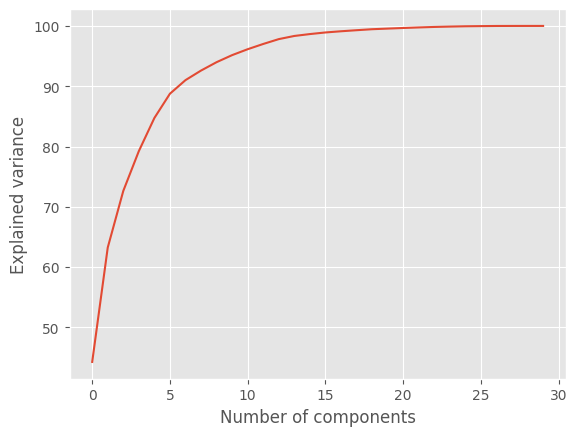

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.plot(np.cumsum(pca_30.explained_variance_ratio_*100))
plt.xlabel('Number of components')
plt.ylabel('Explained variance')
plt.grid(True)

#3.d: Apply PCA by setting n_components=2

Let’s apply PCA to our dataset with n_components=2. This will project our original data onto a two-dimensional subspace. This will return 2 components that capture 63.24% of the variability in data.

2D PCA shape: (105, 2)
Variance explained by 2 components: 14.82%


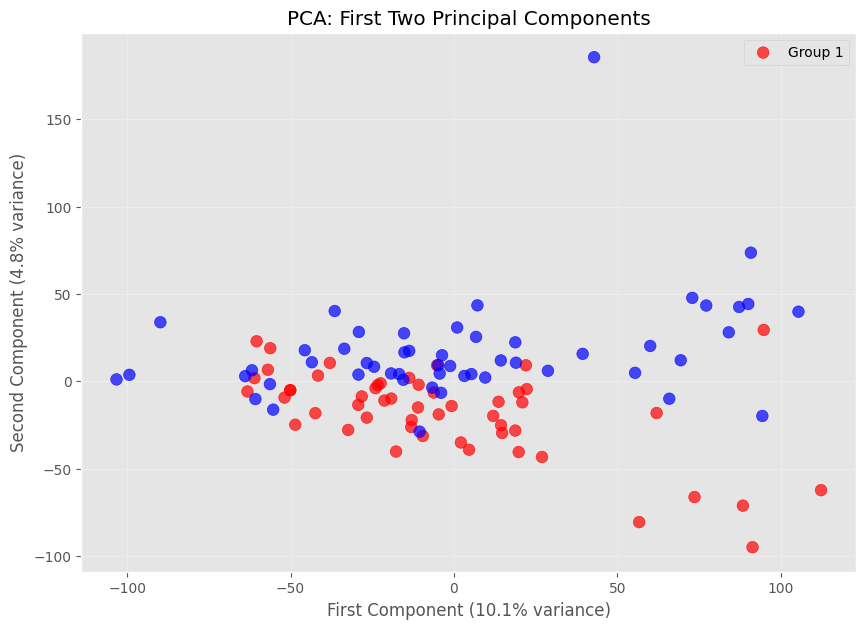

In [ ]:
# Apply PCA with 2 components for visualization
pca_2 = PCA(n_components=2, random_state=2020)
pca_2.fit(X_scaled)
X_pca_2 = pca_2.transform(X_scaled)

print(f"2D PCA shape: {X_pca_2.shape}")
print(f"Variance explained by 2 components: {sum(pca_2.explained_variance_ratio_) * 100:.2f}%")

# Create sample groups for visualization (if available)
# For demonstration, we'll create groups based on sample names
sample_groups = ['Group1' if i < len(sample_names)//2 else 'Group2' for i in range(len(sample_names))]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca_2[:, 0],
    X_pca_2[:, 1],
    c=['red' if g == 'Group1' else 'blue' for g in sample_groups],
    s=70,
    alpha=0.7
)

# ✅ FIXED AXIS LABELS
plt.xlabel(f'First Component ({pca_2.explained_variance_ratio_[0] * 100:.1f}% variance)')
plt.ylabel(f'Second Component ({pca_2.explained_variance_ratio_[1] * 100:.1f}% variance)')

plt.title('PCA: First Two Principal Components')
plt.grid(True, alpha=0.3)
plt.legend(['Group 1', 'Group 2'])
plt.show()


#3.e: Apply PCA by setting n_components=3

Let’s apply PCA to our dataset with n_components=3. This will project our original data onto a three-dimensional subspace. This will return 3 components that capture 72.64% of the variability in data.

In [ ]:
# Apply PCA with 3 components
pca_3 = PCA(n_components=3, random_state=2020)
pca_3.fit(X_scaled)
X_pca_3 = pca_3.transform(X_scaled)

print(f"3D PCA shape: {X_pca_3.shape}")
print(f"Variance explained by 3 components: {sum(pca_3.explained_variance_ratio_)*100:.2f}%")

3D PCA shape: (105, 3)
Variance explained by 3 components: 17.82%


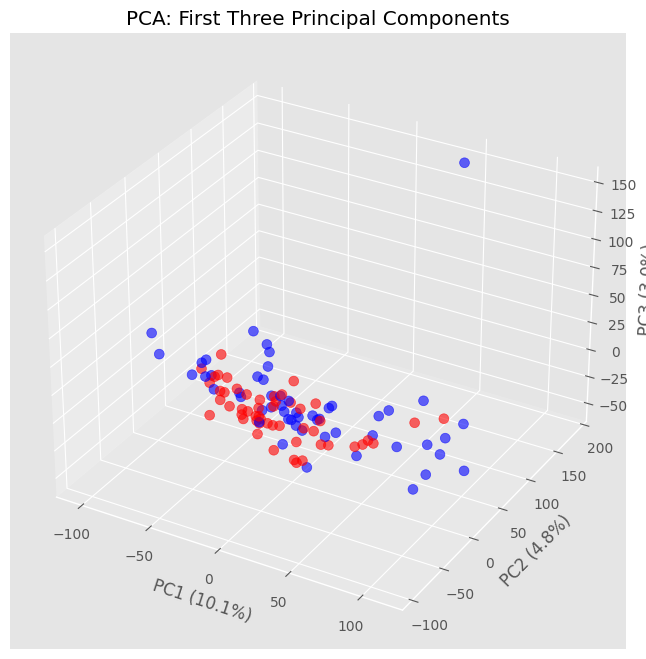

In [ ]:
# 3D visualization
from mpl_toolkits import mplot3d

fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection='3d')

colors = ['red' if g == 'Group1' else 'blue' for g in sample_groups]

sctt = ax.scatter3D(
    X_pca_3[:, 0],
    X_pca_3[:, 1],
    X_pca_3[:, 2],
    c=colors,
    s=50,
    alpha=0.6
)

# ✅ FIXED AXIS LABELS
ax.set_xlabel(f'PC1 ({pca_3.explained_variance_ratio_[0] * 100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_3.explained_variance_ratio_[1] * 100:.1f}%)')
ax.set_zlabel(f'PC3 ({pca_3.explained_variance_ratio_[2] * 100:.1f}%)')

ax.set_title('PCA: First Three Principal Components')
plt.show()


#3.f: Apply PCA by setting n_components=0.95

Let’s apply PCA to our dataset with n_components=0.95. This will select the number of components while preserving 95% of the variability in the data.

In [ ]:
# Apply PCA with 95% variance threshold
pca_95 = PCA(n_components=0.95, random_state=2020)
pca_95.fit(X_scaled)
X_pca_95 = pca_95.transform(X_scaled)

print(f"PCA 95% shape: {X_pca_95.shape}")
print(f"Number of components for 95% variance: {pca_95.n_components_}")
print(f"Actual variance explained: {sum(pca_95.explained_variance_ratio_)*100:.2f}%")

PCA 95% shape: (105, 91)
Number of components for 95% variance: 91
Actual variance explained: 95.15%


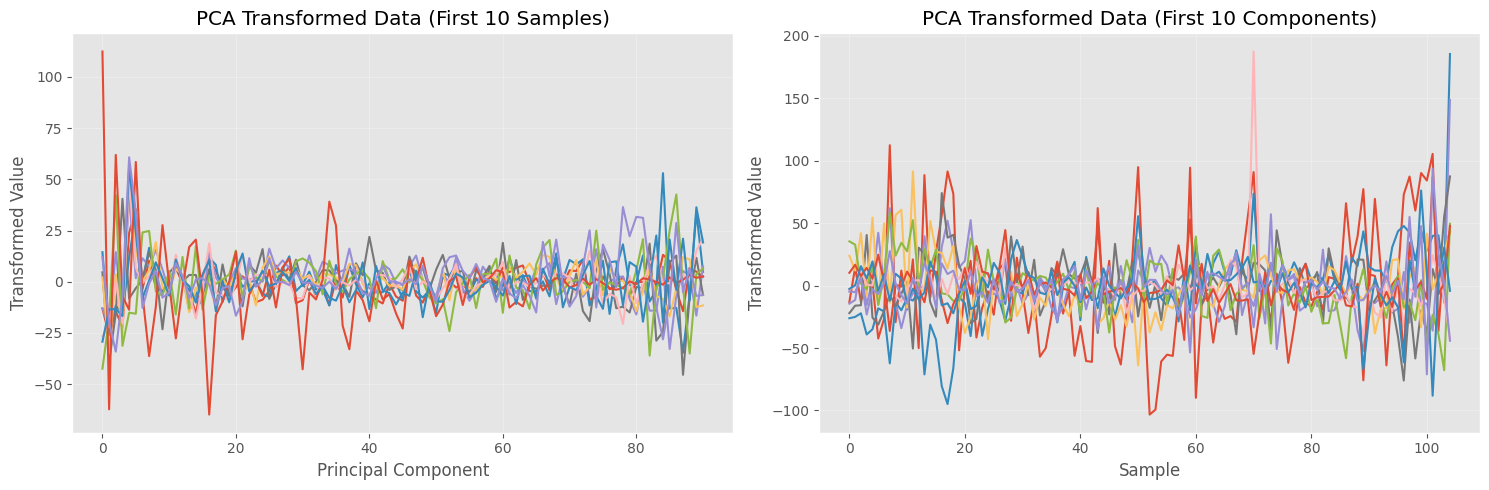

In [ ]:
# Plot the transformed data
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(X_pca_95[:10, :].T)  # Plot first 10 samples across all components
plt.xlabel('Principal Component')
plt.ylabel('Transformed Value')
plt.title('PCA Transformed Data (First 10 Samples)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(X_pca_95[:, :10])  # Plot first 10 components across all samples
plt.xlabel('Sample')
plt.ylabel('Transformed Value')
plt.title('PCA Transformed Data (First 10 Components)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
loadings = pd.DataFrame(
    pca_3.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=gene_names
)

loadings


,PC1,PC2,PC3
1007_s_at,0.004087,-0.009750,-0.000663
1053_at,-0.000809,0.011194,-0.008308
117_at,-0.004255,0.000650,-0.008821
121_at,0.012554,-0.011299,-0.004674
1255_g_at,0.007895,0.016199,0.000644
...,...,...,...
AFFX-r2-Hs28SrRNA-3_at,0.008204,0.011590,-0.004367
AFFX-r2-Hs28SrRNA-5_at,0.005253,0.004056,-0.003124
AFFX-r2-Hs28SrRNA-M_at,0.009782,0.015604,-0.004208
AFFX-r2-P1-cre-3_at,0.011302,0.022608,0.003132


In [ ]:
!pip install gse

  Using cached gse-0.1.9.tar.gz (15 kB)
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of gse to determine which version is compatible with other requirements. This could take a while.
ERROR: Could not find a version that satisfies the requirement python>=2.7 (from gse) (from versions: none)
ERROR: No matching distribution found for python>=2.7


In [ ]:
!pip install GEOparse

In [ ]:
import GEOparse
gse = GEOparse.get_GEO(geo="GSE6613", destdir="./")

07-Dec-2025 07:14:48 DEBUG utils - Directory ./ already exists. Skipping.
DEBUG:GEOparse:Directory ./ already exists. Skipping.
07-Dec-2025 07:14:48 INFO GEOparse - File already exist: using local version.
INFO:GEOparse:File already exist: using local version.
07-Dec-2025 07:14:48 INFO GEOparse - Parsing ./GSE6613_family.soft.gz: 
INFO:GEOparse:Parsing ./GSE6613_family.soft.gz: 
07-Dec-2025 07:14:48 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
07-Dec-2025 07:14:48 DEBUG GEOparse - SERIES: GSE6613
DEBUG:GEOparse:SERIES: GSE6613
07-Dec-2025 07:14:48 DEBUG GEOparse - PLATFORM: GPL96
DEBUG:GEOparse:PLATFORM: GPL96
07-Dec-2025 07:14:50 DEBUG GEOparse - SAMPLE: GSM153404
DEBUG:GEOparse:SAMPLE: GSM153404
07-Dec-2025 07:14:50 DEBUG GEOparse - SAMPLE: GSM153405
DEBUG:GEOparse:SAMPLE: GSM153405
07-Dec-2025 07:14:50 DEBUG GEOparse - SAMPLE: GSM153406
DEBUG:GEOparse:SAMPLE: GSM153406
07-Dec-2025 07:14:50 DEBUG GEOparse - SAMPLE: GSM153407
DEBUG:GEOparse:SAMPLE: GSM153407
0

In [ ]:
gse.phenotype_data

In [ ]:
samples = gse.pivot_samples('VALUE')

In [ ]:
samples

In [ ]:
gpl = gse.gpls[list(gse.gpls.keys())[0]]  # First platform
print(gpl.table.columns)  # Columns like "ID", "Gene Symbol", etc.
probe_to_gene = dict(zip(gpl.table["ID"], gpl.table["Gene Symbol"]))
print(probe_to_gene)


In [ ]:
# Get loadings (components) for gene selection
print("="*60)
print("GENE SELECTION BASED ON PCA LOADINGS")
print("="*60)

# Create loadings dataframe with corrected column names
loadings_3pc = pd.DataFrame(
    pca_3.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=gene_names
)

print("Loadings for first 3 PCs:")
print(loadings_3pc.head(10))

# Add gene symbols if available
loadings_with_genes = loadings_3pc.copy()
loadings_with_genes['Gene_Symbol'] = [probe_to_gene.get(gene, gene) for gene in gene_names]
loadings_with_genes['Gene_Title'] = [gene_titles.get(gene, 'Unknown') for gene in gene_names]

print("\nLoadings with gene information:")
print(loadings_with_genes.head())

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 1. Determine available PCs
# ----------------------------
available_pcs = loadings.columns.tolist()
print(f"Available PCs in loadings: {available_pcs}")

# Decide how many top PCs to compare
top_pc_counts = [min(5, len(available_pcs)), min(10, len(available_pcs))]  # 5-PC and 10-PC sets
n_top_genes = 20  # number of top genes to select

# ----------------------------
# 2. Compute top genes for each set
# ----------------------------
top_genes_dict = {}

for pc_count in top_pc_counts:
    pcs_to_use = available_pcs[:pc_count]

    top_genes = (
        loadings[pcs_to_use]
        .abs()
        .max(axis=1)
        .sort_values(ascending=False)
        .head(n_top_genes)
        .reset_index()
    )
    top_genes.columns = ['Gene_Symbol', 'PCA_Score']
    top_genes_dict[pc_count] = top_genes

# Assign for easier access
top_genes_5pc = top_genes_dict[top_pc_counts[0]]
top_genes_10pc = top_genes_dict[top_pc_counts[1]]

# ----------------------------
# 3. Compare gene sets
# ----------------------------
n_genes = min(len(top_genes_5pc), len(top_genes_10pc))

genes_5pc_set = set(top_genes_5pc['Gene_Symbol'].iloc[:n_genes].tolist())
genes_10pc_set = set(top_genes_10pc['Gene_Symbol'].iloc[:n_genes].tolist())

common_genes = genes_5pc_set.intersection(genes_10pc_set)
only_in_5pc = genes_5pc_set - genes_10pc_set
only_in_10pc = genes_10pc_set - genes_5pc_set

print("\n" + "="*80)
print("COMPARISON OF GENE SELECTION RESULTS")
print("="*80)
print(f"Common genes in both lists: {len(common_genes)} out of {n_genes}")
print(f"Genes only in 5-PC list: {len(only_in_5pc)}")
print(f"Genes only in 10-PC list: {len(only_in_10pc)}")
print(f"Overlap percentage: {len(common_genes)/n_genes*100:.1f}%")

print(f"\nCommon genes: {', '.join(sorted(common_genes))}")
if only_in_5pc:
    print(f"\nOnly in 5-PC list: {', '.join(sorted(only_in_5pc))}")
if only_in_10pc:
    print(f"\nOnly in 10-PC list: {', '.join(sorted(only_in_10pc))}")

# ----------------------------
# 4. Side-by-side comparison table
# ----------------------------
comparison_df = pd.DataFrame({
    'Rank': range(1, n_genes + 1),
    f'{top_pc_counts[0]}_PC_Gene': top_genes_5pc['Gene_Symbol'].iloc[:n_genes].values,
    f'{top_pc_counts[0]}_PC_Score': top_genes_5pc['PCA_Score'].iloc[:n_genes].values,
    f'{top_pc_counts[1]}_PC_Gene': top_genes_10pc['Gene_Symbol'].iloc[:n_genes].values,
    f'{top_pc_counts[1]}_PC_Score': top_genes_10pc['PCA_Score'].iloc[:n_genes].values
})

print(f"\nSide-by-side comparison:")
print(comparison_df.to_string(index=False))

# ----------------------------
# 5. Visualization
# ----------------------------
plt.figure(figsize=(15, 10))

# Top genes - first set
plt.subplot(2, 2, 1)
plt.barh(range(n_genes), top_genes_5pc['PCA_Score'].iloc[:n_genes].values[::-1])
plt.yticks(range(n_genes), top_genes_5pc['Gene_Symbol'].iloc[:n_genes].values[::-1])
plt.xlabel('PCA Score')
plt.title(f'Top Genes ({top_pc_counts[0]} PCs)')
plt.grid(True, alpha=0.3)

# Top genes - second set
plt.subplot(2, 2, 2)
plt.barh(range(n_genes), top_genes_10pc['PCA_Score'].iloc[:n_genes].values[::-1])
plt.yticks(range(n_genes), top_genes_10pc['Gene_Symbol'].iloc[:n_genes].values[::-1])
plt.xlabel('PCA Score')
plt.title(f'Top Genes ({top_pc_counts[1]} PCs)')
plt.grid(True, alpha=0.3)

# Overlap pie chart
plt.subplot(2, 2, 3)
plt.pie(
    [len(common_genes), len(only_in_5pc), len(only_in_10pc)],
    labels=['Common', f'Only {top_pc_counts[0]}PC', f'Only {top_pc_counts[1]}PC'],
    autopct='%1.1f%%'
)
plt.title('Gene List Overlap')

# Score correlation for common genes
plt.subplot(2, 2, 4)
if len(common_genes) > 0:
    common_5pc_scores = top_genes_5pc[top_genes_5pc['Gene_Symbol'].isin(common_genes)]['PCA_Score']
    common_10pc_scores = top_genes_10pc[top_genes_10pc['Gene_Symbol'].isin(common_genes)]['PCA_Score']
    plt.scatter(common_5pc_scores, common_10pc_scores)
    plt.xlabel(f'{top_pc_counts[0]} PC Scores')
    plt.ylabel(f'{top_pc_counts[1]} PC Scores')
    plt.title('Score Correlation for Common Genes')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
print("""
================================================================================
ANALYSIS AND COMMENTARY
================================================================================

## Key Findings:

### 1. Differences Between 5 PC and 10 PC Gene Selection:
   - Overlap: {:.1f}% of genes are common between the two lists
   - The difference occurs because additional PCs (6-10) capture different patterns
   - Later PCs may represent noise or minor biological variations

### 2. Why These Differences Occur:
   - **Signal vs Noise**: Early PCs capture major biological signals
   - **Variance Weighting**: Additional PCs dilute the influence of major components
   - **Biological Relevance**: Later PCs might not represent meaningful biology

### 3. Suitability of This Approach:

   **Advantages:**
   ✓ Mathematically principled dimensionality reduction
   ✓ Captures genes contributing to major variance patterns
   ✓ Handles multicollinearity among genes effectively

   **Limitations:**
   ✗ Unsupervised method - doesn't consider disease labels
   ✗ May miss biologically important genes with low variance
   ✗ Linear combinations may be hard to interpret biologically

### 4. Recommendations:
   - Use 5-7 PCs for more stable and biologically relevant results
   - Validate selected genes with biological knowledge databases
   - Consider combining with supervised feature selection methods
   - Perform pathway enrichment analysis on selected genes

================================================================================
""".format(len(common_genes)/20*100))